In [12]:
import os
import re
import joblib
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as sk
from sklearn.feature_extraction import text
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

# GOALS OF THE PROJECT:

1. Find and load appropiate datasets, and preprocess them.
2. Perform exploratory data analysis (EDA) to understand the distribution of spam and ham emails.
3. Convert text data to numerical features with different vectorization techniques (CountVectorizer, TfidfVectorizer).
4. Train a different classification models (Naive Bayes, XGBoost, Decision Tree, Support Vector Machines).
5. Evaluate the model's performance and reach a conclusion.

In [26]:
## Load datasets
df1 = pd.read_csv("../data/raw/emails.csv")
df2 = pd.read_csv("../data/raw/spam_ham_dataset.csv")

## Cleaning and harmonizing datasets
df1['text'] = df1['text'].str.replace(r'^subject:\s*', '', case=False, regex=True)
df1["text"] = df1["text"].str.strip()

df2["text"] = df2["subject"].fillna("") + " " + df2["body"].fillna("")
df2["spam"] = df2["label"].map({"ham": 0, "spam": 1})
df2.drop(columns=["source_folder", "filename", "subject", "body", "label"], inplace=True)
df2["text"] = df2["text"].str.strip()

df = pd.concat([df1, df2], ignore_index=True)

In [27]:
# EXPLORATORY  DATA ANALYSIS (EDA)
print('\nDuplicate entries and null values before cleaning:')
missing_values = df.isnull().sum()
print(f"Missing values:\n{missing_values}")
duplicate_entries = df.duplicated().sum()
print(f"Duplicate entries: {duplicate_entries}")

## Remove duplicate entries and missing values
df.drop_duplicates(inplace=True)
df.dropna(inplace=True)

print('\nDuplicate entries and null values after cleaning:')
duplicate_entries = df.duplicated().sum()
print(f"Duplicate entries: {duplicate_entries}")
missing_values = df.isnull().sum()
print(f"Missing values:\n{missing_values}")

## Calculating frequency of ham and spam emails
spam_count = df['spam'].value_counts()
spam_perc = df['spam'].value_counts(normalize=True) * 100
print(f"Ham emails: {spam_count[0]} ({spam_perc[0]:.2f}%), Spam emails: {spam_count[1]} ({spam_perc[1]:.2f})%. Total emails: {len(df)}")

## Cleaning HTML and URLs traces from the email text
clean_html_urls=False
if clean_html_urls:
    def cleaning_html_and_urls(text):
        text = re.sub(r'<style[^>]*>[\s\S]*?</style>', ' ', text, flags=re.IGNORECASE)
        text = re.sub(r'<script[^>]*>[\s\S]*?</script>', ' ', text, flags=re.IGNORECASE)
        text = re.sub(r'<[^>]+>', ' ', text)
        text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
        text = re.sub(r'&\w+;', ' ', text)
        text = re.sub(r'\b[0-9a-f]{6}\b', ' ', text, flags=re.IGNORECASE)
        text = re.sub(r'\b\d+\b', ' ', text)
        return text

    df['text'] = df['text'].apply(cleaning_html_and_urls)

## Creating a list of stop words including common HTML tags and attributes
words_html = [
    'html', 'div', 'style', 'bgcolor', 'cellpadding', 'cellspacing',
    'enron', 'ect', 'vince', 'hou', 'zdnet', 'cnet', 'clickthru',
    'subject', 'list', 'net', 'com', 'font', 'br', 'td', 'tr', 'size', 'color', 'face', 'nbsp', 
    'http', 'com', 'width', 'arial', 'align', 'center', 'www', 
    'table', 'height', 'border', 'href', 'src', 'gif', 'img', 'ffffff', 
    'sans', 'seriff', 'verdana', 'helvetica', 'family', 'font-size', 'weight', 'style', '000'
]

personalised_stop_words = list(text.ENGLISH_STOP_WORDS.union(words_html))


Duplicate entries and null values before cleaning:
Missing values:
text    0
spam    0
dtype: int64
Duplicate entries: 3210

Duplicate entries and null values after cleaning:
Duplicate entries: 0
Missing values:
text    0
spam    0
dtype: int64
Ham emails: 8648 (72.84%), Spam emails: 3224 (27.16)%. Total emails: 11872


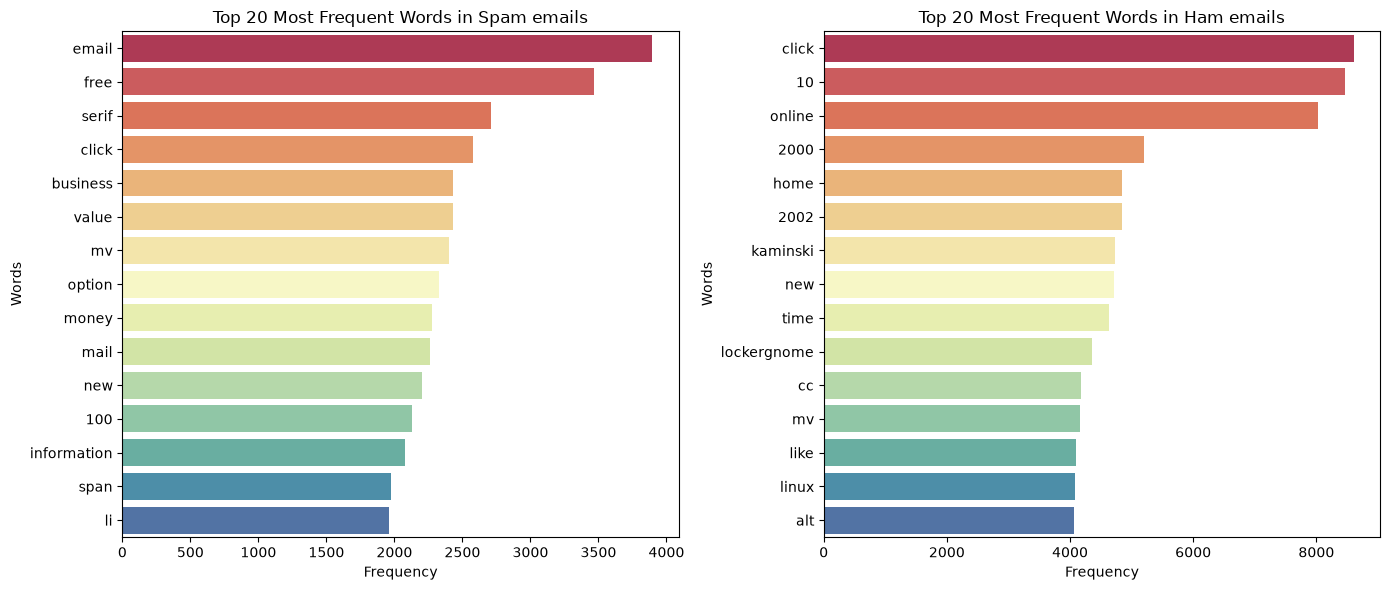

In [15]:
def plot_top_words(axes, df, top_n = 20, stop_words = None, title = ""):

    vectorizer = CountVectorizer(stop_words=stop_words)
    X = vectorizer.fit_transform(df['text'])
    feature_names = vectorizer.get_feature_names_out()
    word_count = np.asarray(X.sum(axis=0)).flatten()
    word_freq = dict(zip(feature_names, word_count))
    top_words = sorted(word_freq.items(), key=lambda x: x[1], reverse=True)
    top_words = top_words[:top_n]
    
    sns.barplot(ax = axes, 
                x=[word[1] for word in top_words],
                y=[word[0] for word in top_words],
                hue=[word[0] for word in top_words],
                palette='Spectral')
    axes.set_title(title)
    axes.set_xlabel('Frequency')
    axes.set_ylabel('Words')
    


spam_emails = df[df['spam'] == 1]
ham_emails = df[df['spam'] == 0]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_top_words(axes[0], spam_emails, top_n=15, stop_words=personalised_stop_words, title="Top 20 Most Frequent Words in Spam emails")
plot_top_words(axes[1], ham_emails , top_n=15, stop_words=personalised_stop_words, title="Top 20 Most Frequent Words in Ham emails")
plt.tight_layout()
plt.show()

In [16]:
## Dividing the dataset into training and testing sets
X = df['text']
y = df['spam']  

X_train,X_test,y_train,y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [17]:
## Training the different models
# set tot TRUE to retrain the models, else it will load them form disk using joblib
training = False

if training:
    pipe = Pipeline([
        ('vec', CountVectorizer()),
        ('model', MultinomialNB())
    ])

    vectorizer = [
        CountVectorizer(stop_words=personalised_stop_words, token_pattern=r"(?u)\b\w+\b|[$!?]"),
        TfidfVectorizer(stop_words=personalised_stop_words, token_pattern=r"(?u)\b\w+\b|[$!?]")
    ]

    models = {
        'multinomial_nb': {
            'vec': vectorizer,
            'vec__ngram_range': [(1, 1), (1, 2)],
            'model': [MultinomialNB()],
            'model__alpha': [0.01, 0.1, 0.5, 1.0],
            'model__fit_prior': [True, False]
        },
        'svc': {
            'vec': vectorizer,
            'vec__ngram_range': [(1, 1), (1, 2)],
            'model': [SVC(random_state=42)],
            'model__C': [0.1, 1.0, 10.0],
            'model__kernel': ['linear', 'rbf'],
            'model__class_weight': [None, 'balanced']
        },
        'random_forest': {
            'vec': vectorizer,
            'vec__ngram_range': [(1, 1), (1, 2)],
            'model': [RandomForestClassifier(random_state=42)],
            'model__n_estimators': [100, 200],
            'model__max_depth': [20, 50, None],
            'model__min_samples_split': [2, 5],
            'model__class_weight': [None, 'balanced']
        }
    }

    best_models = {}

    for name, params in models.items():
        grid = GridSearchCV(estimator=pipe, param_grid=params, cv=5, scoring='f1', n_jobs=6)
        grid.fit(X_train, y_train)
        
        best_models[name] = {
            'estimator': grid.best_estimator_,
            'best_params': grid.best_params_,
            'cv_score': grid.best_score_
        }

        print(f'Completed training of model: {name}')

    joblib.dump(best_models, '../models/best_models.joblib')
else:
    best_models = joblib.load('../models/best_models.joblib')


In [18]:
## Obtaining predictions and classification reports for the best models on the test set
# set tot FALSE to reevalute the models, else it will load them form disk using joblib
testing = False

if testing:

    results_test = {}

    for name, data in best_models.items():
        best_estimator = data['estimator']
        y_pred = best_estimator.predict(X_test)
        
        results_test[name] = classification_report(
            y_test, 
            y_pred, 
            output_dict=True, 
            target_names=['ham', 'spam'])

        if hasattr(best_estimator, "predict_proba"):
            y_proba = best_estimator.predict_proba(X_test)[:, 1]
        else:
            y_proba = best_estimator.decision_function(X_test)
        
        results_test[name]['y_pred'] = y_pred
        results_test[name]['y_proba'] = y_proba

    joblib.dump(results_test, '../results/results_test.joblib')
else:
    results_test = joblib.load('../results/results_test.joblib')

In [19]:
## Comparing different models on the test split

df_comparison = pd.DataFrame({
    name: {
        'precision_spam': metrics['spam']['precision'],
        'recall_spam': metrics['spam']['recall'],
        'f1_spam': metrics['spam']['f1-score'],
        'accuracy': metrics['accuracy'],
        'cv_f1_train': best_models[name]['cv_score']
    }

for name, metrics in results_test.items()}).T

df_comparison.sort_values(by='f1_spam', ascending=False)
df_comparison.to_csv('../results/model_comparison.csv', index=True)

df_comparison

,precision_spam,recall_spam,f1_spam,accuracy,cv_f1_train
multinomial_nb,0.992114,0.975194,0.983581,0.991158,0.975213
svc,0.979495,0.962791,0.971071,0.984421,0.968809
random_forest,0.969183,0.975194,0.972179,0.984842,0.954485


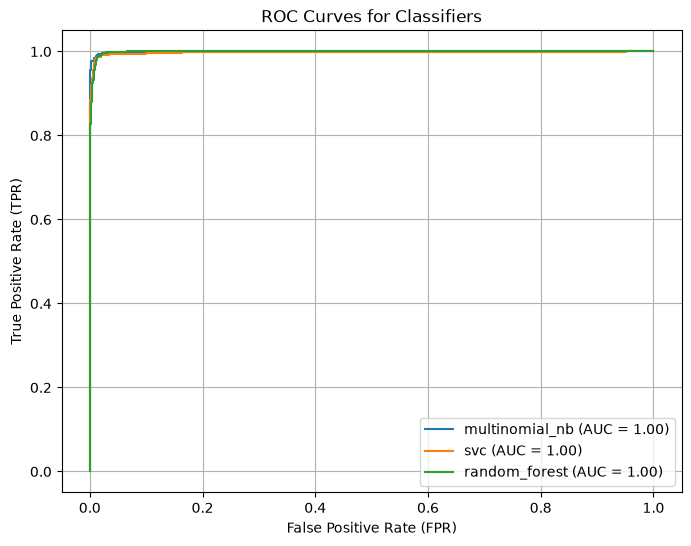

<Figure size 640x480 with 0 Axes>

In [20]:
## AUC_ROC Curve
roc_data = {}

models = [
    'multinomial_nb',
    'svc',
    'random_forest'
]

for model in models:
    y_proba = results_test[model]['y_proba']
    fpr, tpr, thresholds = roc_curve(y_test, results_test[model]['y_proba'])
    auc = roc_auc_score(y_test, y_proba)

    roc_data[model] = {
        'fpr': fpr,
        'tpr': tpr,
        'thresholds': thresholds,
        'auc': auc
    } 

plt.figure(figsize=(8, 6), dpi=100)

for model in models:
    plt.plot(roc_data[model]['fpr'], roc_data[model]['tpr'], label = f"{model} (AUC = {roc_data[model]['auc']:.2f})")

plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curves for Classifiers')
plt.grid(True)
plt.legend()
plt.show()
plt.savefig('../results/roc_curves.png', dpi=300, bbox_inches='tight')

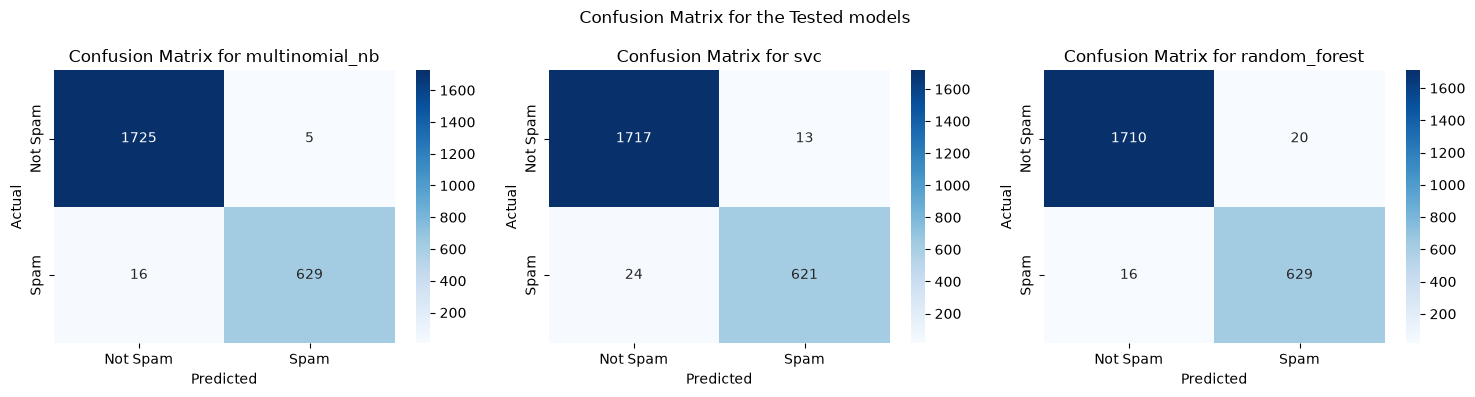

In [21]:
n_models = len(models)
ncols = min(3, n_models)
nrows = math.ceil(n_models / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 4*nrows), squeeze=False)
axes_flat = axes.ravel()

for i, model in enumerate(models):
    y_pred = results_test[model]['y_pred']
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, ax = axes_flat[i], annot=True, fmt='d', cmap='Blues', xticklabels=['Not Spam', 'Spam'], yticklabels=['Not Spam', 'Spam'])
    axes_flat[i].set_title(f'Confusion Matrix for {model}')
    axes_flat[i].set_xlabel('Predicted')
    axes_flat[i].set_ylabel('Actual')

plt.suptitle('Confusion Matrix for the Tested models')
plt.tight_layout()  
plt.savefig('../results/confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()